In [119]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [120]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]

testes = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]


Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. A solução é segmentar pela cor. Ou seja, em ves de ler a imagem em tons de cinzento, esta sera lida com as cores originais e usa-se o fundo azul como referência. 

Porque funciona: no fundo azul, B é bastante maior que R e G, mesmo nas zonas de sombra (fica mais escuro, mas continua azul). Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. Os valores 40 e 20 são o ponto de partida, e deves ajustá-los vendo as máscaras.

O 255 - fundo funciona porque fundo é um array uint8 só com 0 e 255: onde era 255 (fundo) passa a 0, e onde era 0 (peça) passa a 255. Assim, o treino_bin tem todas as imagens em binario, ou seja, peças a branco e fundo a preto.

Medimos a instensidade em cada canal BGR em diferentes sítios na imagem (canto esquerdo, centro e canto direito), para ver o intervalo em que cada canal variava, e desta forma, definir de uma maneira mais rigorosa onde é o fundo, eliminando possíveis erros, como haver valores fora dos intervalos definidos e partes do fundo (como as bordas) serem detetadas como peças.  

Canto esquerdo:  [234 164  73]
Centro:  [198 124  66]
Canto direito [221 149  71]


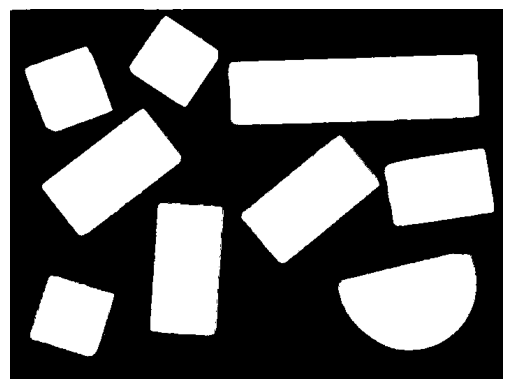

In [121]:

#Binarização

#treino_bin = [cv2.threshold(img, 140, 255, cv2.THRESH_BINARY)[1] for img in treino]

def segmentar(img):
    fundo = cv2.inRange(img, (150, 90, 0), (255, 200, 110))   # (B, G, R) min e max
    return 255 - fundo                                        # peças = branco, fundo = preto


#estes valores estão em bgr, pq a imagem foi lida assim
print("Canto esquerdo: ", treino[0][10, 10])      # canto
print("Centro: ", treino[0][260, 350])    # centro (zona de fundo)
print("Canto direito", treino[0][500, 20])     # outro canto
treino_bin = [segmentar(img) for img in treino]


plt.imshow(treino_bin[0],cmap="gray")
plt.axis("off")
plt.show()


#hist = cv2.calcHist([treino[2]], [0], None, [256], [0, 256])


Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para colocar a branco partes das peças (como as bolinhas) que por algum motivo foram consideradas fundo e estão a preto. 

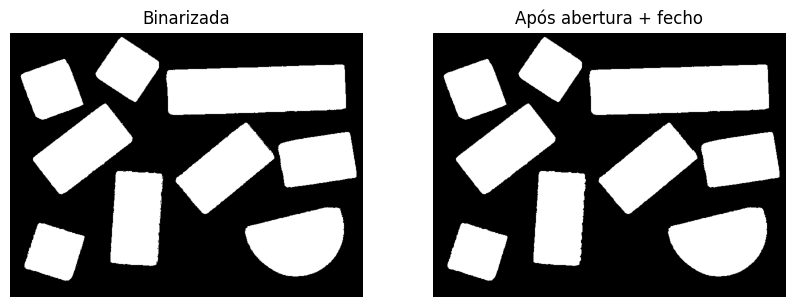

In [122]:
#Operadores Morfológicos

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

def limpar(bin_):
    bin_ = cv2.morphologyEx(bin_, cv2.MORPH_OPEN, kernel)    # abertura
    bin_ = cv2.morphologyEx(bin_, cv2.MORPH_CLOSE, kernel)   # fecho
    return bin_

treino_limpo = [limpar(b) for b in treino_bin]


fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(treino_bin[0], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(treino_limpo[0], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")
plt.show()